# Portada

**UNIVERSIDAD AUTONOMA DEL ESTADO DE MEXICO (UAEMex)**

**Investigación de Operaciones**

**Ingeniería en Computación**

**ACTIVIDAD: Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook**

**Práctica: 2. Ruta Crítica (PERT/CPM)**

**Integrantes del equipo:**
 - David Alberto Ruiz Gonzalez
 - Alexia Guadalupe Sanchez Zamora

**Fecha:**: 18 noviembre de 2026

# Título del problema

**Planeación de un proyecto de desarrollo de software con el Método de la Ruta Crítica (CPM)**

## Descripción y planteamiento

Un equipo de TI desarrollará e implementará un sistema web. El proyecto se divide en **12 actividades** con duraciones (en semanas) y relaciones de precedencia conocidas.

**Objetivo:** calcular para cada actividad el inicio temprano (ES), fin temprano (EF), inicio tardío (LS), fin tardío (LF) y la holgura, para determinar la **ruta crítica** y la **duración mínima total** del proyecto.

### Formulación matemática

Para cada actividad $j$ con duración $d_j$ y conjunto de predecesoras $P(j)$ y sucesoras $S(j)$:

**Paso hacia adelante (forward pass):**

$$ES_j=\max_{i\in P(j)} EF_i \;\;(0 \text{ si no tiene predecesoras}),\qquad EF_j=ES_j+d_j$$

**Paso hacia atrás (backward pass):**

$$LF_j=\min_{k\in S(j)} LS_k \;\;(\text{= duración del proyecto si no tiene sucesoras}),\qquad LS_j=LF_j-d_j$$

**Holgura total:**

$$H_j = LS_j-ES_j = LF_j-EF_j$$

Una actividad es **crítica** si $H_j=0$. La **ruta crítica** es la cadena de actividades críticas desde el inicio hasta el fin; su duración es la **duración mínima del proyecto** $T=\max_j EF_j$.

## Paso 1. Importación de bibliotecas

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


## Paso 2. Definición de datos

Formato: `"ID": (descripción, duración en semanas, [predecesoras])`.

In [2]:
actividades = {
    "A": ("Levantamiento de requisitos",     3, []),
    "B": ("Diseño de la base de datos",      4, ["A"]),
    "C": ("Diseño de la interfaz (UI/UX)",   5, ["A"]),
    "D": ("Configuración de servidores",     3, ["A"]),
    "E": ("Desarrollo del backend",          8, ["B", "D"]),
    "F": ("Desarrollo del frontend",         6, ["C"]),
    "G": ("Integración de APIs",             4, ["E", "F"]),
    "H": ("Pruebas unitarias",               3, ["E"]),
    "I": ("Pruebas de integración",          4, ["G", "H"]),
    "J": ("Documentación técnica",           3, ["B", "C"]),
    "K": ("Capacitación a usuarios",         2, ["I", "J"]),
    "L": ("Despliegue a producción",         2, ["K"]),
}

datos = pd.DataFrame(
    [(k, v[0], v[1], ", ".join(v[2]) or "-") for k, v in actividades.items()],
    columns=["ID", "Actividad", "Duración (sem)", "Predecesoras"])
print(datos.to_string(index=False))
print("\nTotal de actividades:", len(actividades))

ID                     Actividad  Duración (sem) Predecesoras
 A   Levantamiento de requisitos               3            -
 B    Diseño de la base de datos               4            A
 C Diseño de la interfaz (UI/UX)               5            A
 D   Configuración de servidores               3            A
 E        Desarrollo del backend               8         B, D
 F       Desarrollo del frontend               6            C
 G           Integración de APIs               4         E, F
 H             Pruebas unitarias               3            E
 I        Pruebas de integración               4         G, H
 J         Documentación técnica               3         B, C
 K       Capacitación a usuarios               2         I, J
 L       Despliegue a producción               2            K

Total de actividades: 12


## Paso 3. Construcción de la red de precedencias

Se construye un **grafo dirigido** (actividad en el nodo). `topological_generations` agrupa las actividades por "niveles": todas las de un nivel pueden calcularse una vez resueltas las del nivel anterior. Esto nos permite hacer el cálculo y la gráfica **nivel por nivel**.

In [3]:
G = nx.DiGraph()
for k, (desc, dur, preds) in actividades.items():
    G.add_node(k, dur=dur)
    for p in preds:
        G.add_edge(p, k)

niveles = list(nx.topological_generations(G))
for i, nivel in enumerate(niveles):
    print(f"Nivel {i}: {nivel}")

# posiciones para dibujar: una columna por nivel
pos = {}
for i, nivel in enumerate(niveles):
    n = len(nivel)
    for j, nodo in enumerate(nivel):
        pos[nodo] = (i * 2.6, ((n - 1) / 2 - j) * 1.9)

Nivel 0: ['A']
Nivel 1: ['B', 'C', 'D']
Nivel 2: ['F', 'J', 'E']
Nivel 3: ['G', 'H']
Nivel 4: ['I']
Nivel 5: ['K']
Nivel 6: ['L']


Definimos la función de dibujo. Cada nodo muestra: `ID (duración)`, `ES | EF`, `LS | LF` y, al final, la holgura. Los nodos recién calculados se resaltan en amarillo, los críticos en rojo.

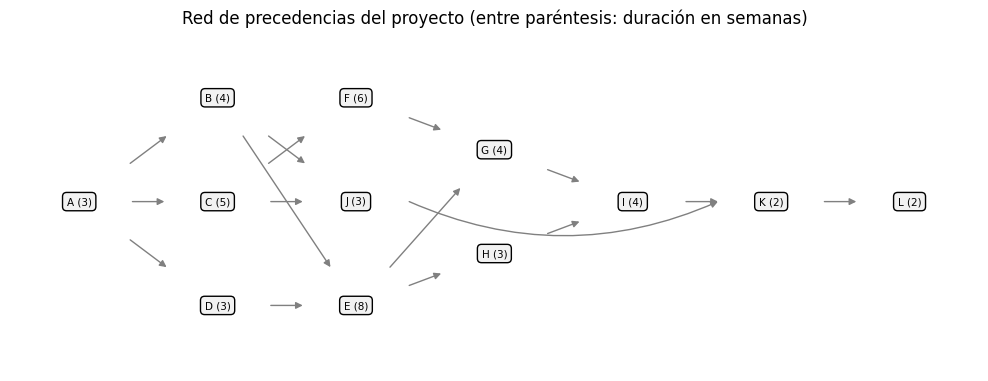

In [4]:
def dibujar(ES=None, EF=None, LS=None, LF=None, holgura=None, nuevos=(),
            criticas=(), titulo=""):
    ES, EF, LS, LF = ES or {}, EF or {}, LS or {}, LF or {}
    fig, ax = plt.subplots(figsize=(12.5, 4.4))
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 1.3, max(xs) + 1.3)
    ax.set_ylim(min(ys) - 1.2, max(ys) + 1.2)
    ax.axis("off")
    cajas = {}
    for n in G.nodes():
        lineas = [f"{n} ({G.nodes[n]['dur']})"]
        if n in ES:
            lineas.append(f"ES={ES[n]}  EF={EF[n]}")
        if n in LS:
            lineas.append(f"LS={LS[n]}  LF={LF[n]}")
        if holgura and n in holgura:
            lineas.append(f"H={holgura[n]}")
        color = "#f2f2f2"
        if n in nuevos:
            color = "#fff2a8"
        if n in criticas:
            color = "#ff9d9d"
        cajas[n] = ax.text(pos[n][0], pos[n][1], "\n".join(lineas), ha="center",
                           va="center", fontsize=7.5, zorder=3,
                           bbox=dict(boxstyle="round,pad=0.4", fc=color, ec="black"))
    crit = set(criticas)
    hw, hh = 1.0, 0.7          # semiancho y semialto aproximados de cada caja
    for u, v in G.edges():
        es_crit = u in crit and v in crit and EF.get(u) == ES.get(v)
        salto = abs(pos[v][0] - pos[u][0]) > 3             # arista que salta niveles
        dx, dy = pos[v][0] - pos[u][0], pos[v][1] - pos[u][1]
        t = min(hw / abs(dx) if dx else 9, hh / abs(dy) if dy else 9)
        ini = (pos[u][0] + t * dx, pos[u][1] + t * dy)     # salida de la caja origen
        fin = (pos[v][0] - t * dx, pos[v][1] - t * dy)     # entrada a la caja destino
        ax.annotate("", xy=fin, xytext=ini, zorder=1,
                    arrowprops=dict(arrowstyle="-|>", lw=2.6 if es_crit else 1,
                                    color="red" if es_crit else "gray",
                                    connectionstyle="arc3,rad=0.22" if salto else "arc3",
                                    shrinkA=0, shrinkB=0))
    ax.set_title(titulo)
    plt.show()


dibujar(titulo="Red de precedencias del proyecto (entre paréntesis: duración en semanas)")

## Paso 4. Paso hacia adelante (ES y EF)

Se recorre la red nivel por nivel. Para cada actividad:
$ES = \max(EF \text{ de sus predecesoras})$ y $EF = ES + d$. Después de cada nivel se grafica el avance.

--- Nivel 0 ---
A: ES = sin predecesoras = 0;  EF = 0 + 3 = 3


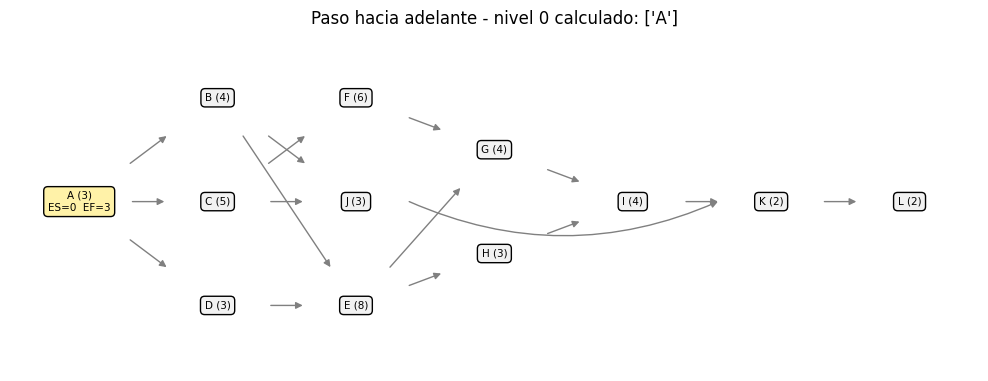

--- Nivel 1 ---
B: ES = max[3] = 3;  EF = 3 + 4 = 7
C: ES = max[3] = 3;  EF = 3 + 5 = 8
D: ES = max[3] = 3;  EF = 3 + 3 = 6


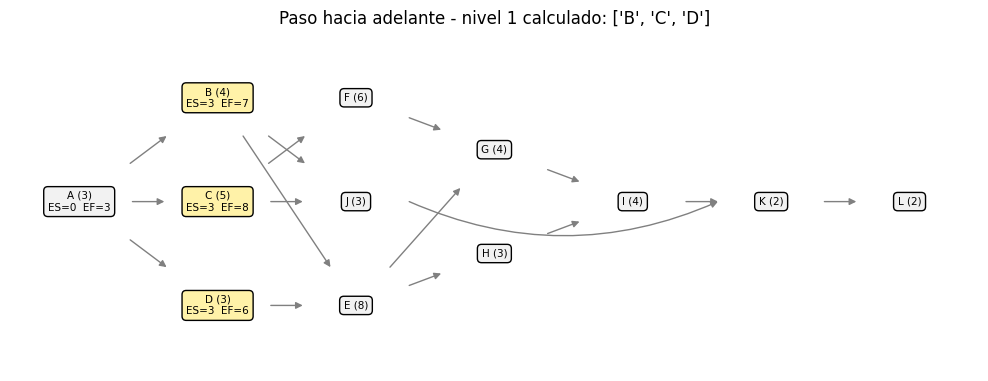

--- Nivel 2 ---
F: ES = max[8] = 8;  EF = 8 + 6 = 14
J: ES = max[7, 8] = 8;  EF = 8 + 3 = 11
E: ES = max[7, 6] = 7;  EF = 7 + 8 = 15


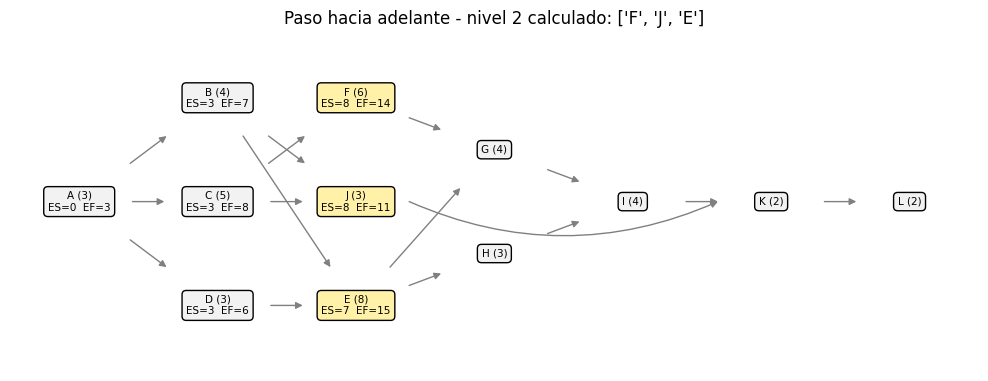

--- Nivel 3 ---
G: ES = max[15, 14] = 15;  EF = 15 + 4 = 19
H: ES = max[15] = 15;  EF = 15 + 3 = 18


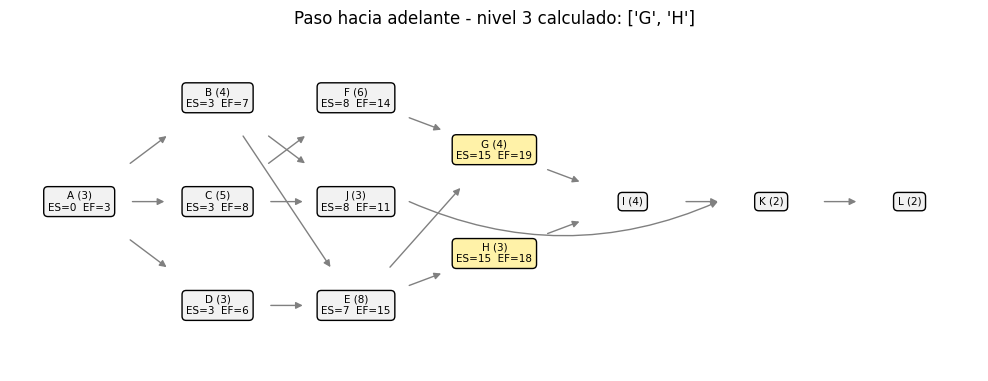

--- Nivel 4 ---
I: ES = max[19, 18] = 19;  EF = 19 + 4 = 23


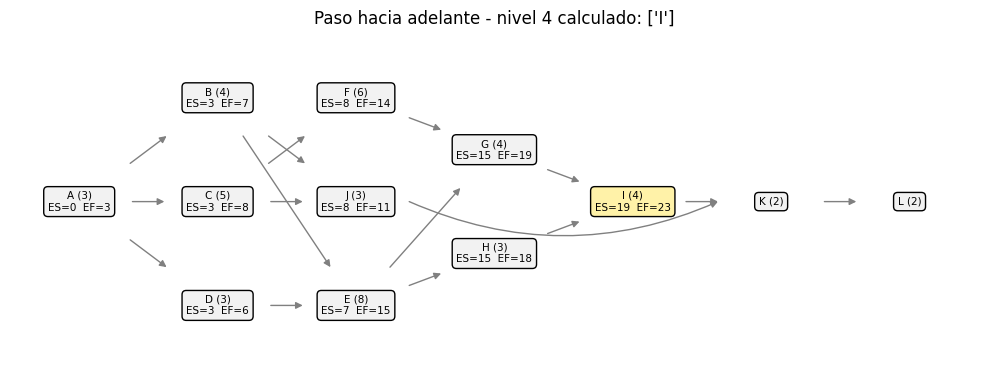

--- Nivel 5 ---
K: ES = max[23, 11] = 23;  EF = 23 + 2 = 25


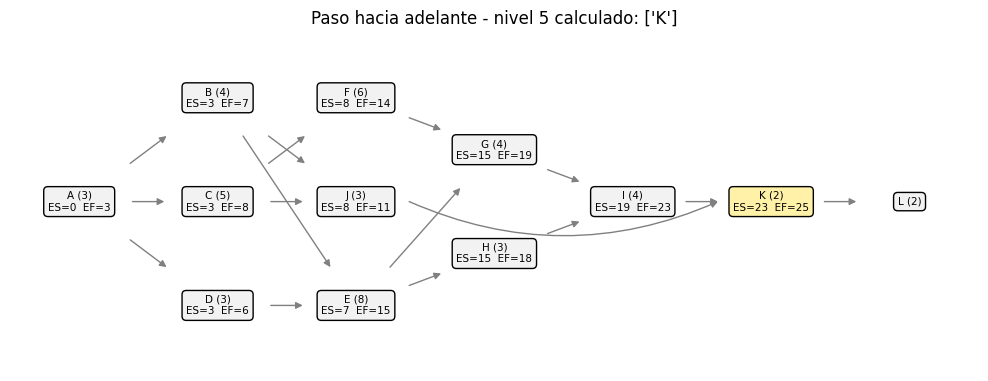

--- Nivel 6 ---
L: ES = max[25] = 25;  EF = 25 + 2 = 27


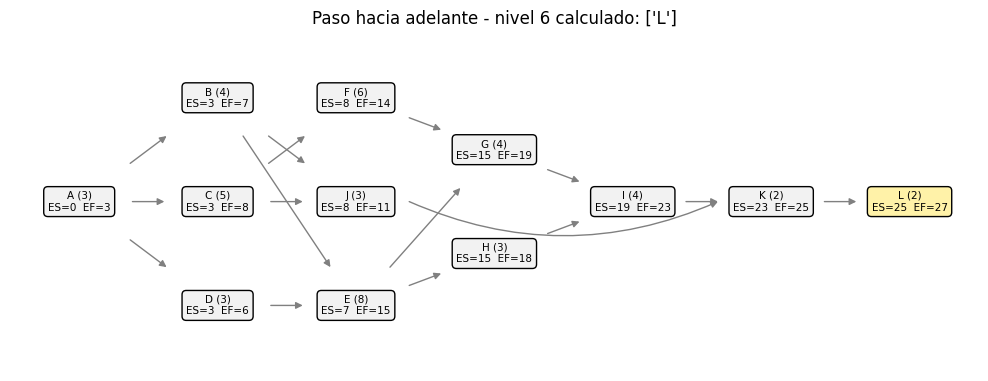


Duración total del proyecto = 27 semanas


In [5]:
ES, EF = {}, {}
for i, nivel in enumerate(niveles):
    print(f"--- Nivel {i} ---")
    for n in nivel:
        preds = actividades[n][2]
        ES[n] = max((EF[p] for p in preds), default=0)
        EF[n] = ES[n] + actividades[n][1]
        detalle = f"max{[EF[p] for p in preds]}" if preds else "sin predecesoras"
        print(f"{n}: ES = {detalle} = {ES[n]};  EF = {ES[n]} + {actividades[n][1]} = {EF[n]}")
    dibujar(ES, EF, nuevos=nivel, titulo=f"Paso hacia adelante - nivel {i} calculado: {nivel}")

duracion = max(EF.values())
print()
print("Duración total del proyecto =", duracion, "semanas")

## Paso 5. Paso hacia atrás (LF y LS)

Se recorre la red en **sentido inverso**. Para cada actividad:
$LF = \min(LS \text{ de sus sucesoras})$ (o la duración total si no tiene sucesoras) y $LS = LF - d$.

--- Nivel 6 ---
L: LF = duración del proyecto = 27;  LS = 27 - 2 = 25


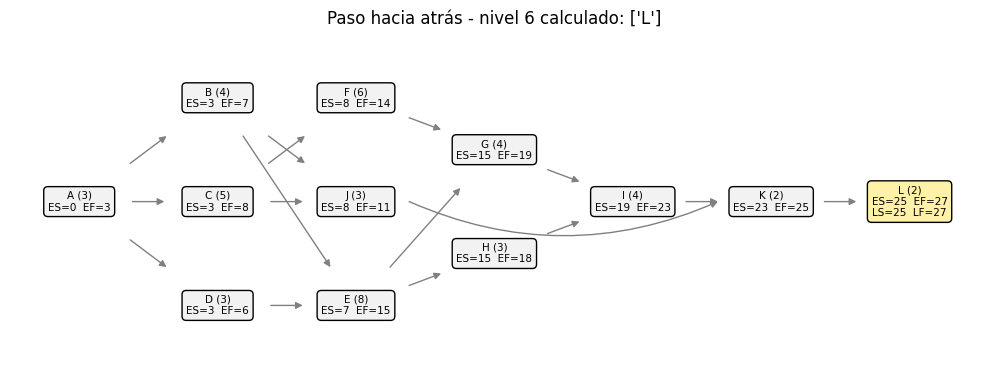

--- Nivel 5 ---
K: LF = min[25] = 25;  LS = 25 - 2 = 23


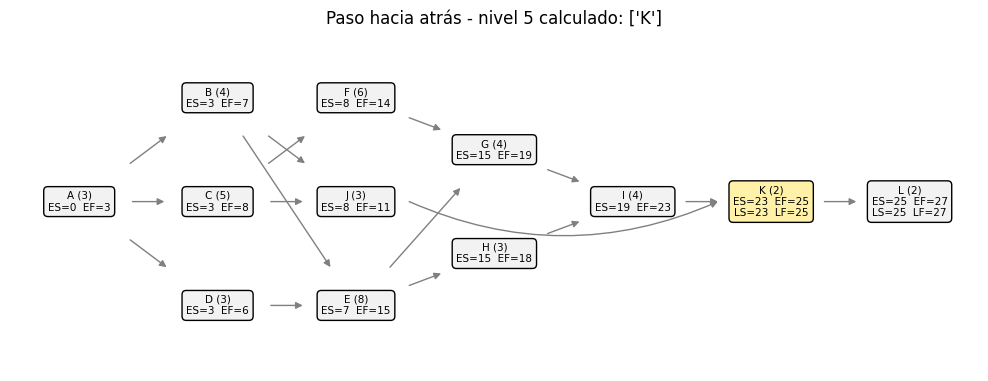

--- Nivel 4 ---
I: LF = min[23] = 23;  LS = 23 - 4 = 19


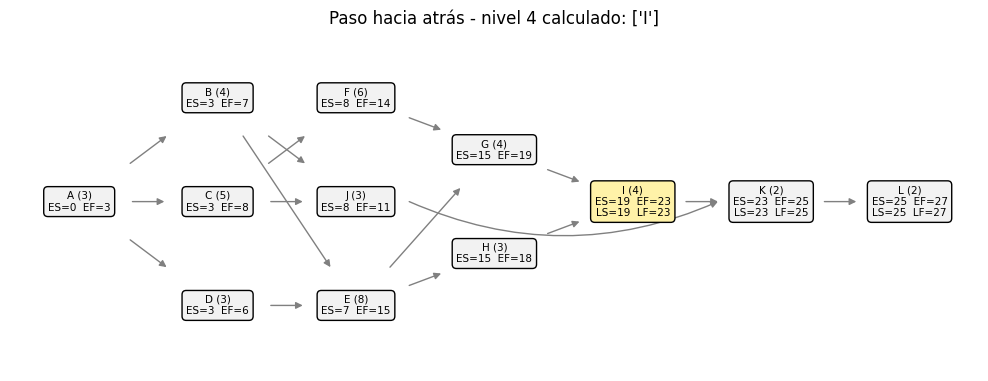

--- Nivel 3 ---
G: LF = min[19] = 19;  LS = 19 - 4 = 15
H: LF = min[19] = 19;  LS = 19 - 3 = 16


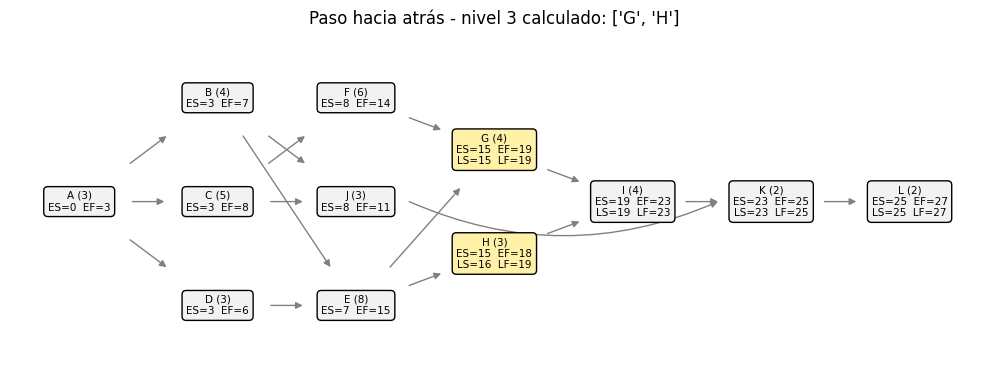

--- Nivel 2 ---
F: LF = min[15] = 15;  LS = 15 - 6 = 9
J: LF = min[23] = 23;  LS = 23 - 3 = 20
E: LF = min[15, 16] = 15;  LS = 15 - 8 = 7


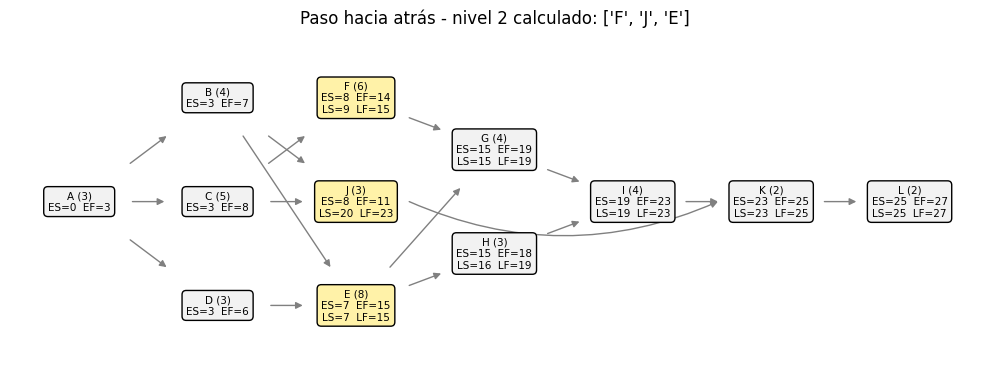

--- Nivel 1 ---
B: LF = min[7, 20] = 7;  LS = 7 - 4 = 3
C: LF = min[9, 20] = 9;  LS = 9 - 5 = 4
D: LF = min[7] = 7;  LS = 7 - 3 = 4


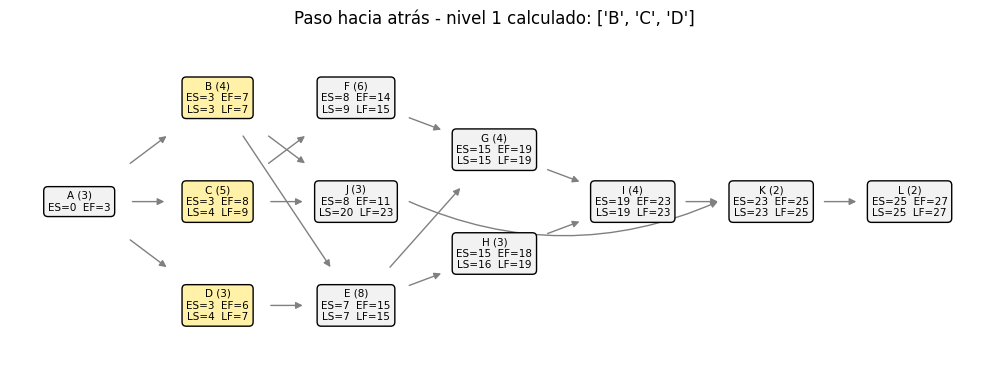

--- Nivel 0 ---
A: LF = min[3, 4, 4] = 3;  LS = 3 - 3 = 0


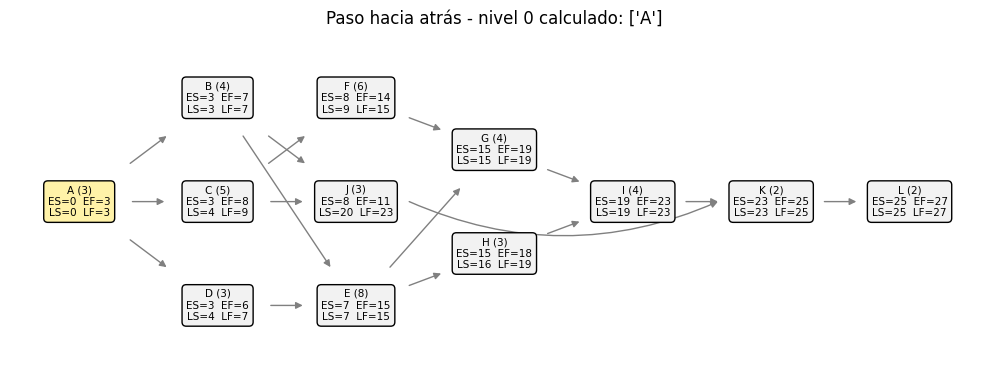

In [7]:
LS, LF = {}, {}
for i, nivel in reversed(list(enumerate(niveles))):
    print(f"--- Nivel {i} ---")
    for n in nivel:
        sucs = list(G.successors(n))
        LF[n] = min((LS[s] for s in sucs), default=duracion)
        LS[n] = LF[n] - actividades[n][1]
        detalle = f"min{[LS[s] for s in sucs]}" if sucs else "duración del proyecto"
        print(f"{n}: LF = {detalle} = {LF[n]};  LS = {LF[n]} - {actividades[n][1]} = {LS[n]}")
    dibujar(ES, EF, LS, LF, nuevos=nivel, titulo=f"Paso hacia atrás - nivel {i} calculado: {nivel}")

## Paso 6. Cálculo de holguras y ruta crítica

$H = LS - ES$. Las actividades con $H=0$ son críticas: cualquier retraso en ellas retrasa todo el proyecto.

In [8]:
holgura = {n: LS[n] - ES[n] for n in actividades}
criticas = [n for n in nx.topological_sort(G) if holgura[n] == 0]

tabla = pd.DataFrame({
    "Actividad": [actividades[n][0] for n in actividades],
    "Dur": [actividades[n][1] for n in actividades],
    "ES": [ES[n] for n in actividades],
    "EF": [EF[n] for n in actividades],
    "LS": [LS[n] for n in actividades],
    "LF": [LF[n] for n in actividades],
    "Holgura": [holgura[n] for n in actividades],
    "¿Crítica?": ["SÍ" if holgura[n] == 0 else "no" for n in actividades],
}, index=list(actividades))
tabla.index.name = "ID"
print(tabla.to_string())

print()
print("Ruta crítica:", " -> ".join(criticas))
print("Suma de duraciones críticas:", sum(actividades[n][1] for n in criticas), "semanas")
print("Duración total del proyecto:", duracion, "semanas")

                        Actividad  Dur  ES  EF  LS  LF  Holgura ¿Crítica?
ID                                                                       
A     Levantamiento de requisitos    3   0   3   0   3        0        SÍ
B      Diseño de la base de datos    4   3   7   3   7        0        SÍ
C   Diseño de la interfaz (UI/UX)    5   3   8   4   9        1        no
D     Configuración de servidores    3   3   6   4   7        1        no
E          Desarrollo del backend    8   7  15   7  15        0        SÍ
F         Desarrollo del frontend    6   8  14   9  15        1        no
G             Integración de APIs    4  15  19  15  19        0        SÍ
H               Pruebas unitarias    3  15  18  16  19        1        no
I          Pruebas de integración    4  19  23  19  23        0        SÍ
J           Documentación técnica    3   8  11  20  23       12        no
K         Capacitación a usuarios    2  23  25  23  25        0        SÍ
L         Despliegue a producción    2

## Paso 7. Visualización de la ruta crítica sobre la red

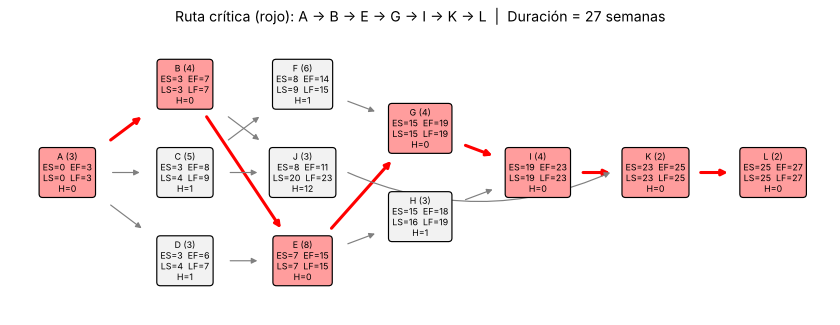

In [8]:
dibujar(ES, EF, LS, LF, holgura, criticas=criticas,
        titulo=f"Ruta crítica (rojo): {' -> '.join(criticas)}  |  Duración = {duracion} semanas")

## Paso 8. Diagrama de Gantt

Las barras rojas son actividades críticas; las azules tienen holgura. La zona rayada indica **cuánto se pueden retrasar** sin afectar la fecha final.

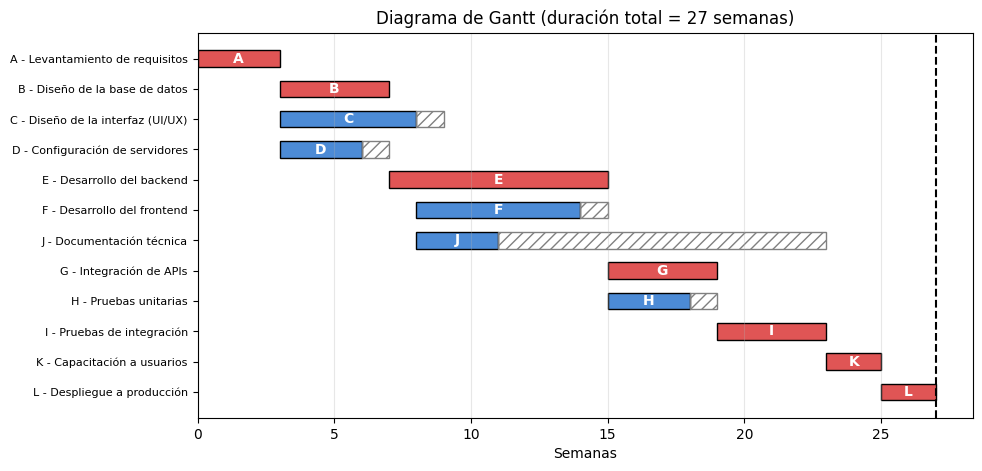

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
orden = sorted(actividades, key=lambda n: (ES[n], n), reverse=True)
for y, n in enumerate(orden):
    crit = holgura[n] == 0
    ax.barh(y, actividades[n][1], left=ES[n], height=0.55,
            color="#e05555" if crit else "#4c8bd6", edgecolor="black")
    if holgura[n] > 0:
        ax.barh(y, holgura[n], left=EF[n], height=0.55, fill=False,
                hatch="///", edgecolor="gray")
    ax.text(ES[n] + actividades[n][1] / 2, y, n, ha="center", va="center",
            color="white", fontweight="bold")
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f"{n} - {actividades[n][0]}" for n in orden], fontsize=8)
ax.axvline(duracion, color="black", ls="--")
ax.set_xlabel("Semanas")
ax.set_title(f"Diagrama de Gantt (duración total = {duracion} semanas)")
ax.grid(axis="x", alpha=0.3)
plt.show()

# Interpretación de resultados

- La **duración mínima del proyecto es 27 semanas**.
- La **ruta crítica es A → B → E → G → I → K → L** (3+4+8+4+4+2+2 = 27). Estas actividades tienen holgura 0: un retraso de una semana en cualquiera de ellas retrasa **todo** el proyecto una semana.
- Las actividades **no críticas** (C, D, F, H, J) tienen holgura; por ejemplo, el frontend (F) puede retrasarse sin afectar la fecha de entrega hasta agotar su holgura, y la documentación (J) tiene la mayor flexibilidad.
- La administración debe **concentrar recursos y seguimiento** en la ruta crítica; para acortar el proyecto hay que reducir la duración de actividades críticas (por ejemplo, añadir desarrolladores al backend, E, la actividad más larga).
- Al acortar actividades críticas, otra ruta puede volverse crítica; el cálculo debe repetirse.

## Aplicación al área de Tecnologías de la Información

- **Gestión de proyectos de software** (cascada, híbridos): estimar fechas de entrega y detectar cuellos de botella.
- **Migraciones de infraestructura y despliegues** (servidores, bases de datos, seguridad) con dependencias estrictas.
- **Planeación de sprints y releases**, y pipelines de CI/CD donde unas tareas dependen de otras.
- Herramientas como MS Project, Jira o Gantt de GitHub Projects usan internamente este mismo cálculo.

## Conclusiones del equipo


El método CPM permitió convertir una lista de actividades con dependencias en un plan cuantitativo: se obtuvo la duración mínima (27 semanas), las holguras de cada actividad y la ruta crítica A-B-E-G-I-K-L. Graficar el paso hacia adelante y hacia atrás por niveles facilitó entender cómo se propagan los tiempos por la red. Esta técnica es muy útil para planear y controlar proyectos de TI.


## Conclusiones individuales

| Integrante | Conclusión individual |
|---|---|
| Conclusion (David Alberto) | *(escribe aquí tu conclusión: qué aprendiste, qué dificultades tuviste y cómo se aplica en TI)* Es muy util esta herrienta de ruta critica, ya que nos podemos dar una idea para el tiempo que tenemos a la hora de realizar sea una actividad, tarea, proyecto o cualquier otra cosa, y cuanto tiempo limite, si tenemos tiempo de sobra o ya no nos queda tiempo y tenemos que iniciar lo antes posible, en papel no resulta tan complicado realizarlo, pero en un entorno de programacion es complejo, pero el lado bueno es que nos facilita la interpretacion de nuestros datos y grafos|
| Conclusion (Alexia Guadalupe)|Con esta práctica aprendí cómo funciona el método de la ruta crítica y cómo permite organizar las actividades de un proyecto, conocer cuánto tiempo se necesita para terminarlo e identificar cuáles tareas no pueden retrasarse. También comprendí la importancia de las holguras y cómo Python nos ayuda a representar y analizar los resultados de una manera más sencilla. |
